In [1]:
# If needed, uncomment this line and run it once:
# %pip install numpy pandas matplotlib seaborn pillow scikit-image scikit-learn joblib tensorflow

import os, zipfile, random, warnings, shutil, json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

from skimage.feature import hog, graycomatrix, graycoprops
from skimage.color import rgb2gray
from skimage.transform import resize

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


In [2]:
# EDIT THIS to match the name/location of your ZIP file.
ZIP_PATH = Path("leaf_images.zip")
EXTRACT_DIR = Path("data/leaf_images_extracted")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

if ZIP_PATH.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)
    print("ZIP extracted to:", EXTRACT_DIR.resolve())
else:
    print("ZIP not found:", ZIP_PATH.resolve())
    print("Move your ZIP beside this notebook or edit ZIP_PATH, then rerun this cell.")

ZIP not found: /content/leaf_images.zip
Move your ZIP beside this notebook or edit ZIP_PATH, then rerun this cell.


In [3]:
from pathlib import Path

print(list(Path("/content").glob("*.zip")))

[PosixPath('/content/Lembu.zip'), PosixPath('/content/Mango selected.zip'), PosixPath('/content/Codiaeum variegatum selected.zip'), PosixPath('/content/unknown.zip'), PosixPath('/content/Herbarium zip.zip'), PosixPath('/content/coccinia grandis selected.zip')]


In [4]:
from pathlib import Path
import zipfile

# Folder where your ZIP files are uploaded
ZIP_FOLDER = Path("/content")

# Folder where all extracted files will be stored
EXTRACT_DIR = Path("/content/leaf_images_extracted")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Find and extract every ZIP file
zip_files = list(ZIP_FOLDER.glob("*.zip"))

for zip_path in zip_files:
    destination = EXTRACT_DIR / zip_path.stem
    destination.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(destination)

    print(f"Extracted: {zip_path.name} → {destination}")

print(f"\nDone! Extracted {len(zip_files)} ZIP file(s).")

Extracted: Lembu.zip → /content/leaf_images_extracted/Lembu
Extracted: Mango selected.zip → /content/leaf_images_extracted/Mango selected
Extracted: Codiaeum variegatum selected.zip → /content/leaf_images_extracted/Codiaeum variegatum selected
Extracted: unknown.zip → /content/leaf_images_extracted/unknown
Extracted: Herbarium zip.zip → /content/leaf_images_extracted/Herbarium zip
Extracted: coccinia grandis selected.zip → /content/leaf_images_extracted/coccinia grandis selected

Done! Extracted 6 ZIP file(s).


In [5]:
for path in Path("/content/leaf_images_extracted").rglob("*"):
    if path.is_dir():
        print("FOLDER:", path)

FOLDER: /content/leaf_images_extracted/unknown
FOLDER: /content/leaf_images_extracted/Mango selected
FOLDER: /content/leaf_images_extracted/Codiaeum variegatum selected
FOLDER: /content/leaf_images_extracted/Lembu
FOLDER: /content/leaf_images_extracted/Herbarium zip
FOLDER: /content/leaf_images_extracted/coccinia grandis selected
FOLDER: /content/leaf_images_extracted/unknown/unknown
FOLDER: /content/leaf_images_extracted/Mango selected/Mango selected
FOLDER: /content/leaf_images_extracted/Codiaeum variegatum selected/Codiaeum variegatum selected
FOLDER: /content/leaf_images_extracted/coccinia grandis selected/coccinia grandis selected


In [6]:
from pathlib import Path

folder = Path("/content/leaf_images_extracted")

for item in folder.iterdir():
    print("Folder/file:", item.name)

Folder/file: unknown
Folder/file: Mango selected
Folder/file: Codiaeum variegatum selected
Folder/file: Lembu
Folder/file: Herbarium zip
Folder/file: coccinia grandis selected


In [7]:
from pathlib import Path

folder = Path("/content/leaf_images_extracted")

if folder.exists():
    for item in sorted(folder.iterdir()):
        print("Folder/file:", item.name)
else:
    print("Extraction folder not found. Check the extraction path.")

Folder/file: Codiaeum variegatum selected
Folder/file: Herbarium zip
Folder/file: Lembu
Folder/file: Mango selected
Folder/file: coccinia grandis selected
Folder/file: unknown


In [8]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def direct_images(folder):
    return [p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTS]

class_dirs = []
for folder in EXTRACT_DIR.rglob("*"):
    if folder.is_dir() and direct_images(folder):
        class_dirs.append(folder)

# Remove nested folders if a parent folder itself is a class directory.
class_dirs = sorted(class_dirs, key=lambda p: str(p).lower())
print("Folders with images found:", len(class_dirs))
for folder in class_dirs[:40]:
    print(f"{folder.name}: {len(direct_images(folder))} images")
if not class_dirs:
    print("No class folders detected. Check that the ZIP contains one folder per class and image files inside them.")

Folders with images found: 6
coccinia grandis selected: 54 images
Codiaeum variegatum selected: 51 images
Herbarium zip: 50 images
Lembu: 60 images
Mango selected: 62 images
unknown: 50 images


In [9]:
# Optional: write the exact five folder names here, for example:
# KNOWN_CLASSES = ["Neem", "Mango", "Oak", "Maple", "Peepal"]
KNOWN_CLASSES = None
UNKNOWN_FOLDER_NAMES = {"unknown", "unidentified", "other", "others", "unknown_leaves"}

folder_by_name = {p.name: p for p in class_dirs}
explicit_unknown_dirs = [p for p in class_dirs if p.name.lower() in UNKNOWN_FOLDER_NAMES]
normal_dirs = [p for p in class_dirs if p.name.lower() not in UNKNOWN_FOLDER_NAMES]

if KNOWN_CLASSES is None:
    ranked = sorted(normal_dirs, key=lambda p: len(direct_images(p)), reverse=True)
    known_dirs = ranked[:5]
else:
    missing = [name for name in KNOWN_CLASSES if name not in folder_by_name]
    if missing:
        raise ValueError(f"These KNOWN_CLASSES were not found: {missing}. Check folder names printed above.")
    known_dirs = [folder_by_name[name] for name in KNOWN_CLASSES]

if len(known_dirs) < 2:
    raise ValueError("At least two known class folders are needed. Check the extracted folder structure.")

known_names = [p.name for p in known_dirs]
unknown_dirs = explicit_unknown_dirs + [p for p in normal_dirs if p not in known_dirs]

records = []
for folder in known_dirs:
    for img_path in direct_images(folder):
        records.append({"image_path": str(img_path.resolve()), "original_class": folder.name, "label": folder.name})
for folder in unknown_dirs:
    for img_path in direct_images(folder):
        records.append({"image_path": str(img_path.resolve()), "original_class": folder.name, "label": "unknown"})
metadata = pd.DataFrame(records).drop_duplicates(subset="image_path").reset_index(drop=True)
print("Known classes:", known_names)
print("Unknown-source folders:", [p.name for p in unknown_dirs])
print("Total images:", len(metadata))
print(metadata["label"].value_counts())
metadata.to_csv("leaf_metadata.csv", index=False)
print("Saved metadata to leaf_metadata.csv")

if not unknown_dirs:
    print("WARNING: No unknown examples found. Add an unknown folder with other leaf species before final evaluation.")
if metadata["label"].nunique() < 3:
    print("WARNING: For this project, aim for five known classes plus unknown. Check the folder names and dataset contents.")

Known classes: ['Mango selected', 'Lembu', 'coccinia grandis selected', 'Codiaeum variegatum selected', 'Herbarium zip']
Unknown-source folders: ['unknown']
Total images: 327
label
Mango selected                  62
Lembu                           60
coccinia grandis selected       54
Codiaeum variegatum selected    51
Herbarium zip                   50
unknown                         50
Name: count, dtype: int64
Saved metadata to leaf_metadata.csv


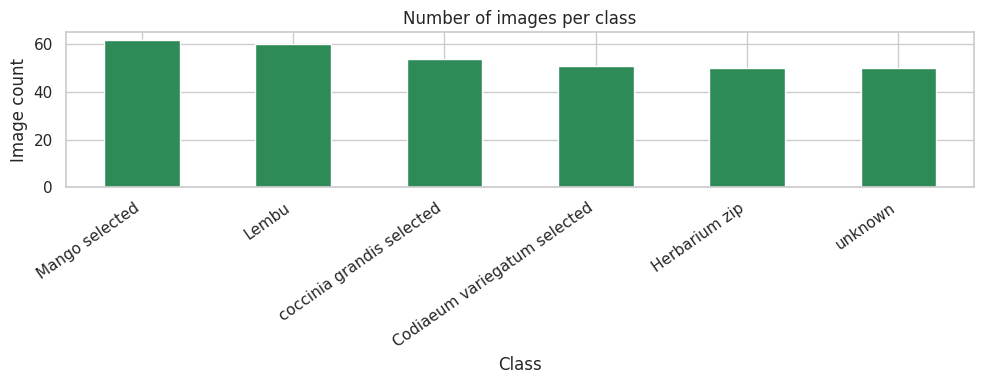

Readable images: 327 of 327


,width,height
count,327.0,327.0
mean,512.0,512.0
std,0.0,0.0
min,512.0,512.0
25%,512.0,512.0
50%,512.0,512.0
75%,512.0,512.0
max,512.0,512.0


Image modes:
mode
RGB    327
Name: count, dtype: int64


In [10]:
# Class counts
counts = metadata["label"].value_counts().sort_values(ascending=False)
ax = counts.plot(kind="bar", figsize=(10, 4), color="seagreen")
ax.set_title("Number of images per class")
ax.set_xlabel("Class")
ax.set_ylabel("Image count")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Image dimensions and readable sample images
sizes, readable = [], []
for row in metadata.itertuples():
    try:
        with Image.open(row.image_path) as im:
            sizes.append({"label": row.label, "width": im.width, "height": im.height, "mode": im.mode})
            readable.append(row.image_path)
    except Exception as exc:
        print("Unreadable image:", row.image_path, "|", exc)
size_df = pd.DataFrame(sizes)
print("Readable images:", len(readable), "of", len(metadata))
display(size_df[["width", "height"]].describe())
print("Image modes:")
print(size_df["mode"].value_counts())

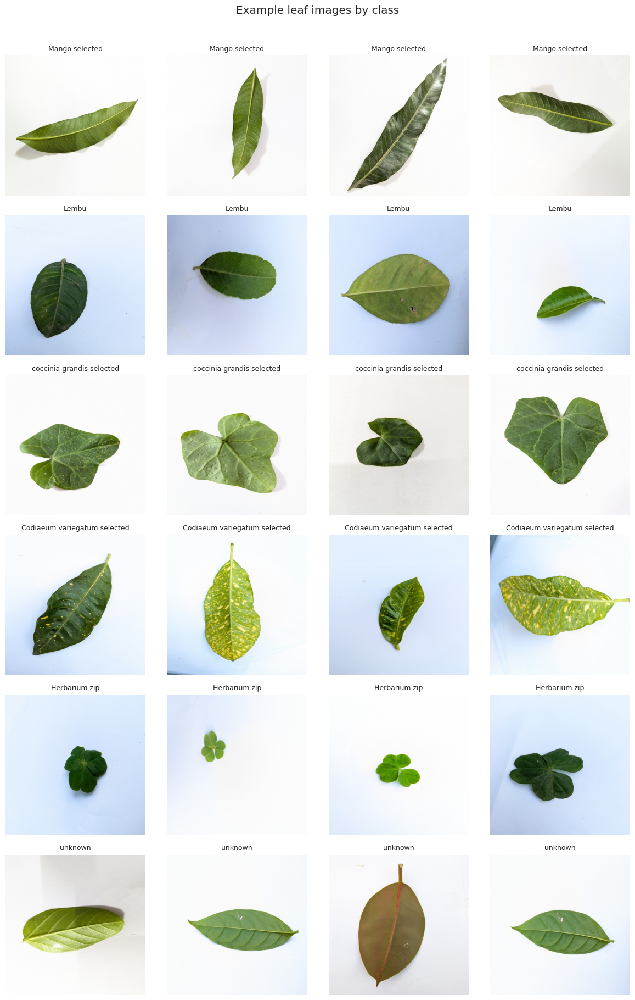

In [11]:
# Sample image montage
sample_df = metadata.groupby("label", group_keys=False).head(4).reset_index(drop=True)
n = len(sample_df)
cols = 4
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
axes = np.array(axes).reshape(-1)
for ax, row in zip(axes, sample_df.itertuples()):
    try:
        img = Image.open(row.image_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(row.label, fontsize=9)
    except Exception:
        ax.set_title("Unreadable")
    ax.axis("off")
for ax in axes[n:]:
    ax.axis("off")
plt.suptitle("Example leaf images by class", y=1.01)
plt.tight_layout()
plt.show()

                              mean_red  mean_green  mean_blue  mean_brightness
label                                                                         
Codiaeum variegatum selected     0.809       0.853      0.820            0.827
Herbarium zip                    0.817       0.867      0.896            0.860
Lembu                            0.820       0.859      0.870            0.850
Mango selected                   0.895       0.902      0.872            0.890
coccinia grandis selected        0.850       0.871      0.813            0.845
unknown                          0.828       0.843      0.780            0.817


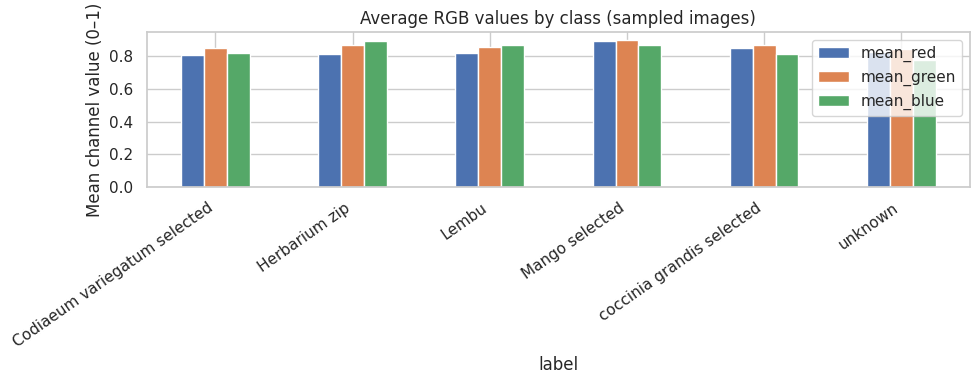

In [12]:
# Approximate average RGB and brightness for a sample of images
colour_rows = []
for row in metadata.sample(min(200, len(metadata)), random_state=SEED).itertuples():
    try:
        img = Image.open(row.image_path).convert("RGB").resize((64, 64))
        arr = np.asarray(img, dtype=np.float32) / 255.0
        colour_rows.append({"label": row.label, "mean_red": arr[:,:,0].mean(),
                            "mean_green": arr[:,:,1].mean(), "mean_blue": arr[:,:,2].mean(),
                            "mean_brightness": arr.mean()})
    except Exception:
        pass
colour_df = pd.DataFrame(colour_rows)
print(colour_df.groupby("label")[["mean_red", "mean_green", "mean_blue", "mean_brightness"]].mean().round(3))
colour_df.groupby("label")[["mean_red", "mean_green", "mean_blue"]].mean().plot(kind="bar", figsize=(10,4))
plt.title("Average RGB values by class (sampled images)")
plt.ylabel("Mean channel value (0–1)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [13]:
# Keep only images that PIL can open
valid_paths = set()
for p in metadata["image_path"]:
    try:
        with Image.open(p) as im:
            im.verify()
        valid_paths.add(p)
    except Exception:
        print("Removing unreadable file:", p)
metadata = metadata[metadata["image_path"].isin(valid_paths)].reset_index(drop=True)

class_counts = metadata["label"].value_counts()
print("Images after cleaning:", len(metadata))
print(class_counts)
if (class_counts < 7).any():
    raise ValueError("Every class needs at least 7 readable images for the stratified train/validation/test split. Add images or remove very small classes.")

train_df, temp_df = train_test_split(metadata, test_size=0.30, random_state=SEED, stratify=metadata["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"])
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")
print("Train labels:\n", train_df["label"].value_counts())
train_df.to_csv("train_metadata.csv", index=False)
val_df.to_csv("validation_metadata.csv", index=False)
test_df.to_csv("test_metadata.csv", index=False)

Images after cleaning: 327
label
Mango selected                  62
Lembu                           60
coccinia grandis selected       54
Codiaeum variegatum selected    51
Herbarium zip                   50
unknown                         50
Name: count, dtype: int64
Train: 228 | Validation: 49 | Test: 50
Train labels:
 label
Mango selected                  43
Lembu                           42
coccinia grandis selected       38
unknown                         35
Herbarium zip                   35
Codiaeum variegatum selected    35
Name: count, dtype: int64


In [14]:
IMG_SIZE = (128, 128)

def extract_features(image_path):
    """Extract RGB colour histograms, HOG shape/edge features, and grayscale statistics."""
    image = Image.open(image_path).convert("RGB").resize(IMG_SIZE)
    rgb = np.asarray(image, dtype=np.uint8)
    features = []
    # Colour histogram: 16 bins for each RGB channel, normalized to sum to 1.
    for channel in range(3):
        hist, _ = np.histogram(rgb[:, :, channel], bins=16, range=(0, 256), density=False)
        hist = hist.astype(np.float32) / max(hist.sum(), 1)
        features.extend(hist)
    # HOG captures local gradients and outlines; grayscale is appropriate for edge structure.
    gray = rgb2gray(rgb)
    hog_features = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True)
    features.extend(hog_features)
    # Simple grayscale intensity statistics
    features.extend([gray.mean(), gray.std()])
    return np.asarray(features, dtype=np.float32)

X_train_feat = np.vstack([extract_features(p) for p in train_df["image_path"]])
X_val_feat = np.vstack([extract_features(p) for p in val_df["image_path"]])
X_test_feat = np.vstack([extract_features(p) for p in test_df["image_path"]])
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()
print("Feature matrix shapes:", X_train_feat.shape, X_val_feat.shape, X_test_feat.shape)

Feature matrix shapes: (228, 8150) (49, 8150) (50, 8150)


In [15]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(C=3.0, kernel="rbf", probability=True,
                       class_weight="balanced", random_state=SEED))
])
svm_model.fit(X_train_feat, y_train)
val_pred_svm = svm_model.predict(X_val_feat)
print("Validation accuracy:", round(accuracy_score(y_val, val_pred_svm), 4))
print("Validation macro-F1:", round(f1_score(y_val, val_pred_svm, average="macro", zero_division=0), 4))

Validation accuracy: 0.7551
Validation macro-F1: 0.7499


In [16]:
IMG_SHAPE = (160, 160)
BATCH_SIZE = 16

class_names = sorted(metadata["label"].unique().tolist())
class_to_id = {name: i for i, name in enumerate(class_names)}
print("Classes used by the CNN:", class_names)

# Decode images and labels into TensorFlow datasets.
def load_image_and_label(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SHAPE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

def make_tf_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].map(class_to_id).to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image_and_label, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(min(len(frame), 1000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_tf_dataset(train_df, training=True)
val_ds = make_tf_dataset(val_df)
test_ds = make_tf_dataset(test_df)
print("TensorFlow datasets created.")

Classes used by the CNN: ['Codiaeum variegatum selected', 'Herbarium zip', 'Lembu', 'Mango selected', 'coccinia grandis selected', 'unknown']
TensorFlow datasets created.


In [17]:
# Download ImageNet weights on the first run; requires internet access.
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SHAPE[0], IMG_SHAPE[1], 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(IMG_SHAPE[0], IMG_SHAPE[1], 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
cnn_model = keras.Model(inputs, outputs)
cnn_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 439ms/step - accuracy: 0.4123 - loss: 1.5230 - val_accuracy: 0.7755 - val_loss: 0.7566
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 411ms/step - accuracy: 0.8246 - loss: 0.5974 - val_accuracy: 0.8980 - val_loss: 0.3565
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 339ms/step - accuracy: 0.9167 - loss: 0.3025 - val_accuracy: 0.9184 - val_loss: 0.2411
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 432ms/step - accuracy: 0.9737 - loss: 0.1919 - val_accuracy: 0.9184 - val_loss: 0.1912
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 343ms/step - accuracy: 0.9561 - loss: 0.1708 - val_accuracy: 0.9592 - val_loss: 0.1448
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 414ms/step - accuracy: 0.9825 - loss: 0.1193 - val_accuracy: 0.9592 - val_loss: 0.1355
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 483ms/step - accuracy: 0.9825 - loss: 0.1097 - val_accuracy: 0.9592 - val_loss: 0.1194
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 317ms/step - accuracy: 0.9912 - loss: 0.0941 - val_accuracy: 

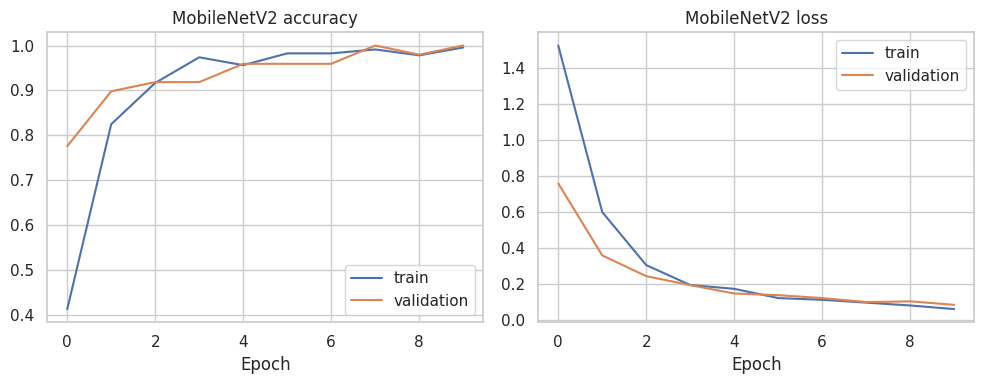

In [18]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                            restore_best_weights=True)
history = cnn_model.fit(train_ds, validation_data=val_ds, epochs=10,
                        callbacks=[early_stop], verbose=1)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("MobileNetV2 accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("MobileNetV2 loss")
plt.xlabel("Epoch")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# SVM test predictions
pred_svm = svm_model.predict(X_test_feat)
prob_svm = svm_model.predict_proba(X_test_feat)

# CNN test predictions
prob_cnn = cnn_model.predict(test_ds, verbose=0)
cnn_ids = np.argmax(prob_cnn, axis=1)
pred_cnn = np.array(class_names)[cnn_ids]

results = pd.DataFrame([
    {"Model": "HOG + RGB histograms + SVM",
     "Accuracy": accuracy_score(y_test, pred_svm),
     "Macro-F1": f1_score(y_test, pred_svm, average="macro", zero_division=0),
     "Macro recall": recall_score(y_test, pred_svm, average="macro", zero_division=0)},
    {"Model": "MobileNetV2 transfer learning",
     "Accuracy": accuracy_score(y_test, pred_cnn),
     "Macro-F1": f1_score(y_test, pred_cnn, average="macro", zero_division=0),
     "Macro recall": recall_score(y_test, pred_cnn, average="macro", zero_division=0)}
])
print(results.round(4).to_string(index=False))

                        Model  Accuracy  Macro-F1  Macro recall
   HOG + RGB histograms + SVM      0.90    0.8982        0.8970
MobileNetV2 transfer learning      0.96    0.9614        0.9606


In [20]:
# SVM test predictions
pred_svm = svm_model.predict(X_test_feat)
prob_svm = svm_model.predict_proba(X_test_feat)

# CNN test predictions
prob_cnn = cnn_model.predict(test_ds, verbose=0)
cnn_ids = np.argmax(prob_cnn, axis=1)
pred_cnn = np.array(class_names)[cnn_ids]

results = pd.DataFrame([
    {"Model": "HOG + RGB histograms + SVM",
     "Accuracy": accuracy_score(y_test, pred_svm),
     "Macro-F1": f1_score(y_test, pred_svm, average="macro", zero_division=0),
     "Macro recall": recall_score(y_test, pred_svm, average="macro", zero_division=0)},
    {"Model": "MobileNetV2 transfer learning",
     "Accuracy": accuracy_score(y_test, pred_cnn),
     "Macro-F1": f1_score(y_test, pred_cnn, average="macro", zero_division=0),
     "Macro recall": recall_score(y_test, pred_cnn, average="macro", zero_division=0)}
])
print(results.round(4).to_string(index=False))

                        Model  Accuracy  Macro-F1  Macro recall
   HOG + RGB histograms + SVM      0.90    0.8982        0.8970
MobileNetV2 transfer learning      0.96    0.9614        0.9606


In [21]:
print("SVM classification report")
print(classification_report(y_test, pred_svm, labels=class_names, zero_division=0))
print("MobileNetV2 classification report")
print(classification_report(y_test, pred_cnn, labels=class_names, zero_division=0))

SVM classification report
                              precision    recall  f1-score   support

Codiaeum variegatum selected       1.00      1.00      1.00         8
               Herbarium zip       0.86      0.86      0.86         7
                       Lembu       0.82      1.00      0.90         9
              Mango selected       0.90      0.90      0.90        10
   coccinia grandis selected       0.88      0.88      0.88         8
                     unknown       1.00      0.75      0.86         8

                    accuracy                           0.90        50
                   macro avg       0.91      0.90      0.90        50
                weighted avg       0.91      0.90      0.90        50

MobileNetV2 classification report
                              precision    recall  f1-score   support

Codiaeum variegatum selected       1.00      1.00      1.00         8
               Herbarium zip       1.00      1.00      1.00         7
                       Lem

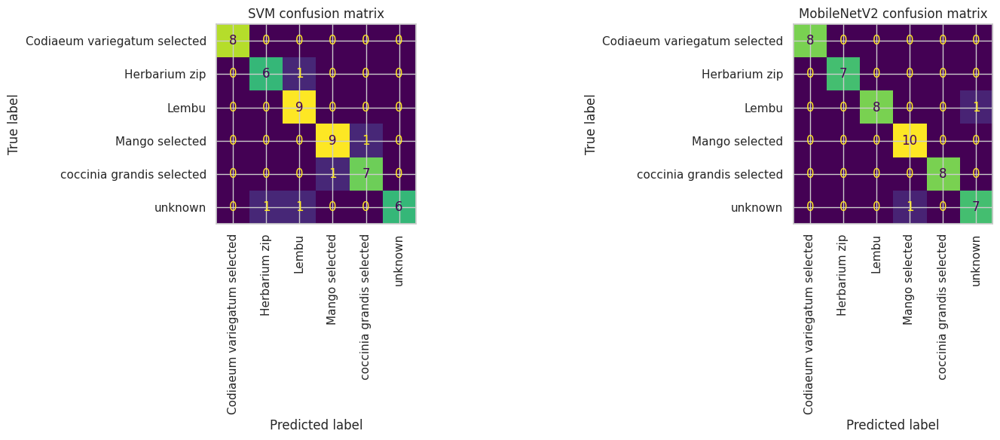

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, pred, title in [(axes[0], pred_svm, "SVM confusion matrix"),
                        (axes[1], pred_cnn, "MobileNetV2 confusion matrix")]:
    cm = confusion_matrix(y_test, pred, labels=class_names)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, xticks_rotation=90, colorbar=False, values_format="d")
    ax.set_title(title)
plt.tight_layout()
plt.show()

SVM mistakes: 5 of 50
CNN mistakes: 2 of 50


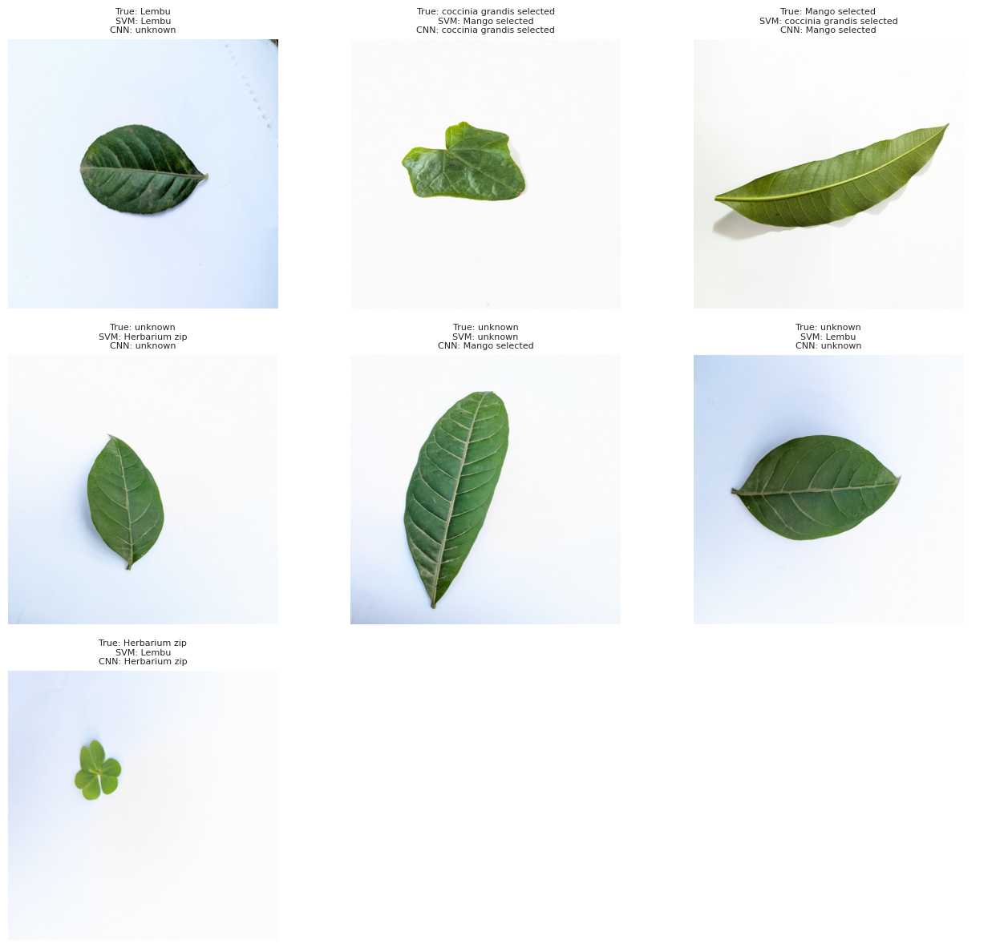

In [23]:
error_df = test_df.copy()
error_df["svm_prediction"] = pred_svm
error_df["cnn_prediction"] = pred_cnn
error_df["svm_correct"] = error_df["label"] == error_df["svm_prediction"]
error_df["cnn_correct"] = error_df["label"] == error_df["cnn_prediction"]
print("SVM mistakes:", int((~error_df["svm_correct"]).sum()), "of", len(error_df))
print("CNN mistakes:", int((~error_df["cnn_correct"]).sum()), "of", len(error_df))

mistakes = error_df[(~error_df["svm_correct"]) | (~error_df["cnn_correct"])].head(12)
if len(mistakes) == 0:
    print("No mistakes in this small test set. This does not guarantee perfect performance on new images.")
else:
    cols = 3
    rows = int(np.ceil(len(mistakes) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(13, 4 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, row in zip(axes, mistakes.itertuples()):
        ax.imshow(Image.open(row.image_path).convert("RGB"))
        ax.set_title(f"True: {row.label}\nSVM: {row.svm_prediction}\nCNN: {row.cnn_prediction}", fontsize=8)
        ax.axis("off")
    for ax in axes[len(mistakes):]: ax.axis("off")
    plt.tight_layout()
    plt.show()

In [24]:
# Get validation probabilities for both models
val_prob_svm = svm_model.predict_proba(X_val_feat)
val_prob_cnn = cnn_model.predict(val_ds, verbose=0)

# Select a simple threshold from the 10th percentile of maximum validation confidence.
# This is a demonstration heuristic; it is not an optimized universal threshold.
svm_threshold = float(np.quantile(val_prob_svm.max(axis=1), 0.10))
cnn_threshold = float(np.quantile(val_prob_cnn.max(axis=1), 0.10))
print("SVM confidence threshold:", round(svm_threshold, 3))
print("MobileNetV2 confidence threshold:", round(cnn_threshold, 3))

def predict_with_unknown_svm(feature_vector, threshold=svm_threshold):
    probs = svm_model.predict_proba(np.asarray(feature_vector).reshape(1, -1))[0]
    idx = int(np.argmax(probs))
    label = svm_model.classes_[idx] if probs[idx] >= threshold else "unknown (low confidence)"
    return label, float(probs[idx])

def predict_with_unknown_cnn(image_path, threshold=cnn_threshold):
    img = Image.open(image_path).convert("RGB").resize(IMG_SHAPE)
    arr = np.asarray(img, dtype=np.float32)
    arr = tf.keras.applications.mobilenet_v2.preprocess_input(arr)
    probs = cnn_model.predict(arr[None, ...], verbose=0)[0]
    idx = int(np.argmax(probs))
    label = class_names[idx] if probs[idx] >= threshold else "unknown (low confidence)"
    return label, float(probs[idx])

SVM confidence threshold: 0.39
MobileNetV2 confidence threshold: 0.808


In [25]:
# EDIT this path to a leaf photo you want to test.
NEW_IMAGE_PATH = "path/to/your/new_leaf.jpg"

if Path(NEW_IMAGE_PATH).exists():
    display(Image.open(NEW_IMAGE_PATH).convert("RGB"))
    svm_label, svm_conf = predict_with_unknown_svm(extract_features(NEW_IMAGE_PATH))
    cnn_label, cnn_conf = predict_with_unknown_cnn(NEW_IMAGE_PATH)
    print(f"SVM prediction: {svm_label} (top probability {svm_conf:.3f})")
    print(f"MobileNetV2 prediction: {cnn_label} (top probability {cnn_conf:.3f})")
else:
    print("Edit NEW_IMAGE_PATH to an existing image path, then rerun this cell.")

Edit NEW_IMAGE_PATH to an existing image path, then rerun this cell.


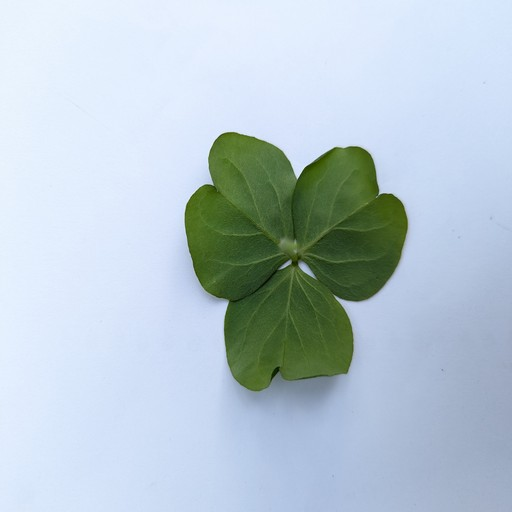

SVM prediction: Herbarium zip (top probability 0.997)
MobileNetV2 prediction: unknown (low confidence) (top probability 0.688)


In [34]:
# EDIT this path to a leaf photo you want to test.
NEW_IMAGE_PATH = "Herbarium Oxalis_15.jpg"  # 👈 PUT YOUR IMAGE NAME HERE

if Path(NEW_IMAGE_PATH).exists():
    display(Image.open(NEW_IMAGE_PATH).convert("RGB"))
    svm_label, svm_conf = predict_with_unknown_svm(extract_features(NEW_IMAGE_PATH))
    cnn_label, cnn_conf = predict_with_unknown_cnn(NEW_IMAGE_PATH)
    print(f"SVM prediction: {svm_label} (top probability {svm_conf:.3f})")
    print(f"MobileNetV2 prediction: {cnn_label} (top probability {cnn_conf:.3f})")
else:
    print("Edit NEW_IMAGE_PATH to an existing image path, then rerun this cell.")

In [33]:
from pathlib import Path

for file in Path.cwd().iterdir():
    if file.is_file():
        print(file.name)

Lembu.zip
test_metadata.csv
train_metadata.csv
Mango selected.zip
Codiaeum variegatum selected.zip
unknown.zip
validation_metadata.csv
Herbarium Oxalis_15.jpg
leaf_metadata.csv
Herbarium zip.zip
coccinia grandis selected.zip


In [35]:
OUTPUT_DIR = Path("project_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
joblib.dump(svm_model, OUTPUT_DIR / "hog_colour_svm.joblib")
cnn_model.save(OUTPUT_DIR / "mobilenetv2_leaf_classifier.keras")

model_notes = {
    "known_classes": known_names,
    "all_model_labels": class_names,
    "svm_confidence_threshold": svm_threshold,
    "mobilenetv2_confidence_threshold": cnn_threshold,
    "image_size_svm": list(IMG_SIZE),
    "image_size_cnn": list(IMG_SHAPE),
    "random_seed": SEED,
    "note": "Unknown confidence threshold is a heuristic; validate with genuinely unseen species and non-leaf images."
}
with open(OUTPUT_DIR / "model_notes.json", "w", encoding="utf-8") as f:
    json.dump(model_notes, f, indent=2)
results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
metadata.to_csv(OUTPUT_DIR / "leaf_metadata.csv", index=False)
print("Saved files:")
for p in sorted(OUTPUT_DIR.iterdir()): print("-", p.name)
print("Metadata and split CSV files are saved in the notebook's working folder too.")

Saved files:
- hog_colour_svm.joblib
- leaf_metadata.csv
- mobilenetv2_leaf_classifier.keras
- model_comparison.csv
- model_notes.json
Metadata and split CSV files are saved in the notebook's working folder too.


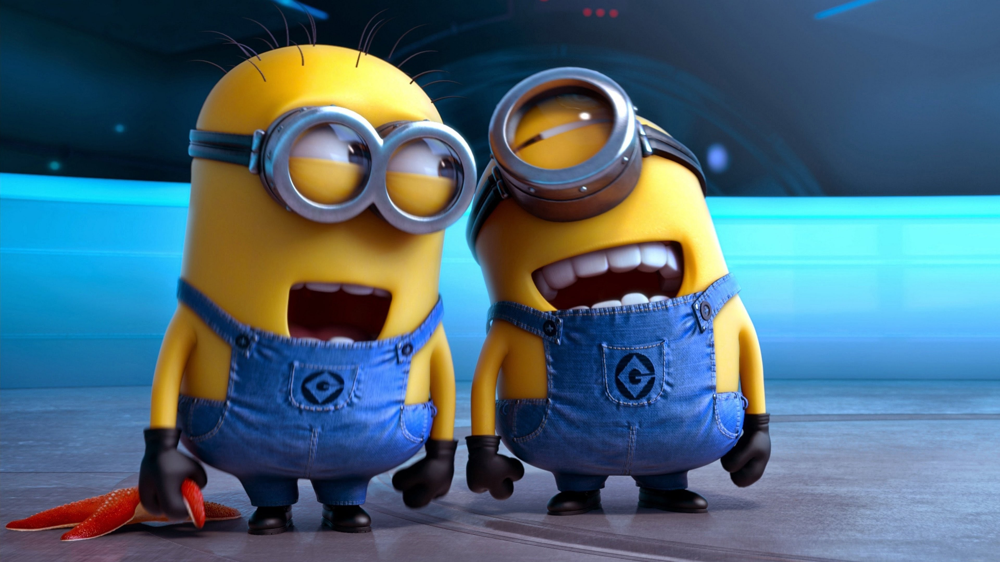

SVM prediction: unknown (top probability 0.744)
MobileNetV2 prediction: Codiaeum variegatum selected (top probability 0.971)


In [36]:
# EDIT this path to a leaf photo you want to test.
NEW_IMAGE_PATH = "/content/minion.jpg"  # 👈 PUT YOUR IMAGE NAME HERE

if Path(NEW_IMAGE_PATH).exists():
    display(Image.open(NEW_IMAGE_PATH).convert("RGB"))
    svm_label, svm_conf = predict_with_unknown_svm(extract_features(NEW_IMAGE_PATH))
    cnn_label, cnn_conf = predict_with_unknown_cnn(NEW_IMAGE_PATH)
    print(f"SVM prediction: {svm_label} (top probability {svm_conf:.3f})")
    print(f"MobileNetV2 prediction: {cnn_label} (top probability {cnn_conf:.3f})")
else:
    print("Edit NEW_IMAGE_PATH to an existing image path, then rerun this cell.")

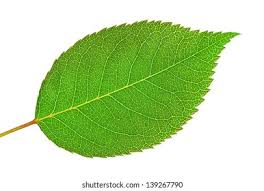

SVM prediction: unknown (top probability 0.608)
MobileNetV2 prediction: unknown (low confidence) (top probability 0.526)


In [38]:
# EDIT this path to a leaf photo you want to test.
NEW_IMAGE_PATH = "/content/leaf.jpg"  # 👈 PUT YOUR IMAGE NAME HERE

if Path(NEW_IMAGE_PATH).exists():
    display(Image.open(NEW_IMAGE_PATH).convert("RGB"))
    svm_label, svm_conf = predict_with_unknown_svm(extract_features(NEW_IMAGE_PATH))
    cnn_label, cnn_conf = predict_with_unknown_cnn(NEW_IMAGE_PATH)
    print(f"SVM prediction: {svm_label} (top probability {svm_conf:.3f})")
    print(f"MobileNetV2 prediction: {cnn_label} (top probability {cnn_conf:.3f})")
else:
    print("Edit NEW_IMAGE_PATH to an existing image path, then rerun this cell.")